# voorbereiding Mini Bacteria Sorter CNN

## Doel

In dit experiment zullen we zien:

- hoe een 8×8-afbeelding als tensor/matrix wordt opgebouwd
- wat 0 en 1 betekenen
- hoe de drie vormen eruitzien.

Wij bouwen hierna stap voor stap een klein Convolutional Neural Network (CNN).


## De afbeeldingen

Een digitale zwart-witafbeelding kan worden voorgesteld als een matrix van getallen.

In dit experiment gebruiken we:

- `0` = zwart
- `1` = wit

Iedere afbeelding bestaat uit 8 rijen en 8 kolommen en bevat dus 64 pixels.

Eerst maken we zelf enkele eenvoudige afbeeldingen. Hierdoor kunnen we precies zien welke gegevens het neurale netwerk later als invoer krijgt.

In [8]:
import torch

# Eenvoudige ronde vorm van 8 × 8 pixels
rond = torch.tensor([
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [1, 1, 1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0]
], dtype=torch.float32)

print(rond)

tensor([[0., 0., 0., 1., 1., 0., 0., 0.],
        [0., 0., 1., 1., 1., 1., 0., 0.],
        [0., 1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [0., 1., 1., 1., 1., 1., 1., 0.],
        [0., 0., 1., 1., 1., 1., 0., 0.],
        [0., 0., 0., 1., 1., 0., 0., 0.]])


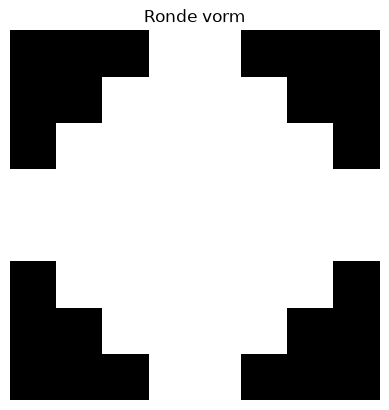

In [9]:
import matplotlib.pyplot as plt

plt.imshow(rond, cmap="gray", vmin=0, vmax=1)
plt.title("Ronde vorm")
plt.axis("off")
plt.show()

In [10]:
# Staafvormige bacterie
staaf = torch.tensor([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=torch.float32)


# Eenvoudige spiraalvorm
spiraal = torch.tensor([
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 1, 1, 0, 0, 1, 1, 0],
    [0, 1, 0, 0, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 1, 0],
    [0, 1, 1, 1, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=torch.float32)

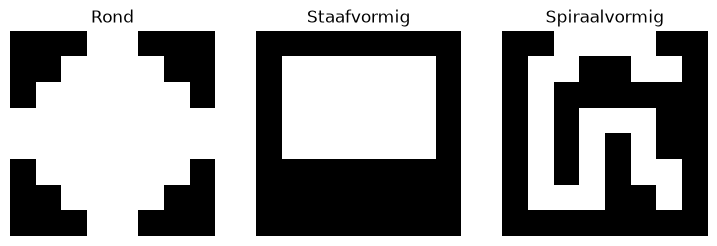

In [11]:
fig, assen = plt.subplots(1, 3, figsize=(9, 3))

afbeeldingen = [rond, staaf, spiraal]
namen = ["Rond", "Staafvormig", "Spiraalvormig"]

for as_, afbeelding, naam in zip(assen, afbeeldingen, namen):
    as_.imshow(afbeelding, cmap="gray", vmin=0, vmax=1)
    as_.set_title(naam)
    as_.axis("off")

plt.show()